# Problem Statement

#### To mitigate the risk of pipeline failures and optimize resource allocation by developing a predictive classification model that determines whether a specific pipeline segment requires maintenance ('Yes' or 'No') based on its structural characteristics and operational age.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("/content/market_pipe_thickness_loss_dataset.csv")
df.head()


,Pipe_Size_mm,Thickness_mm,Material,Grade,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years,Condition
0,800,15.48,Carbon Steel,ASTM A333 Grade 6,300,84.9,16.04,4.91,31.72,2,Moderate
1,800,22.00,PVC,ASTM A106 Grade B,150,14.1,7.38,7.32,33.27,4,Critical
2,400,12.05,Carbon Steel,API 5L X52,2500,0.6,2.12,6.32,52.45,7,Critical
3,1500,38.72,Carbon Steel,API 5L X42,1500,52.7,5.58,6.20,16.01,19,Critical
4,1500,24.32,HDPE,API 5L X65,1500,11.7,12.29,8.58,35.28,20,Critical


In [ ]:
df.shape

(1000, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pipe_Size_mm              1000 non-null   int64  
 1   Thickness_mm              1000 non-null   float64
 2   Material                  1000 non-null   object 
 3   Grade                     1000 non-null   object 
 4   Max_Pressure_psi          1000 non-null   int64  
 5   Temperature_C             1000 non-null   float64
 6   Corrosion_Impact_Percent  1000 non-null   float64
 7   Thickness_Loss_mm         1000 non-null   float64
 8   Material_Loss_Percent     1000 non-null   float64
 9   Time_Years                1000 non-null   int64  
 10  Condition                 1000 non-null   object 
dtypes: float64(5), int64(3), object(3)
memory usage: 86.1+ KB


In [ ]:
df.describe()

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,522.000000,16.073530,1004.100000,42.595600,9.745990,4.886300,46.747560,12.961000
std,443.703587,10.548358,812.843099,41.127071,5.817492,2.901123,46.602553,7.135993
min,50.000000,3.000000,150.000000,-50.000000,0.000000,0.010000,0.080000,1.000000
25%,150.000000,7.357500,300.000000,13.400000,4.492500,2.365000,15.665000,7.000000
50%,300.000000,12.930000,900.000000,41.200000,9.720000,4.915000,31.660000,13.000000
75%,800.000000,23.027500,1500.000000,69.150000,14.832500,7.432500,61.035000,19.000000
max,1500.000000,49.530000,2500.000000,149.700000,20.000000,9.990000,318.750000,25.000000


In [ ]:
def counts_value(df):
  for i in df.columns:
    print(df[i].value_counts())
    print()
counts_value(df)

Pipe_Size_mm
100     94
50      90
250     88
300     84
150     78
1500    77
1200    77
800     75
500     73
200     69
600     67
1000    66
400     62
Name: count, dtype: int64

Thickness_mm
5.10     4
9.94     4
7.34     4
5.21     4
10.21    3
        ..
18.79    1
20.48    1
12.51    1
15.72    1
23.96    1
Name: count, Length: 836, dtype: int64

Material
Fiberglass         219
Carbon Steel       210
Stainless Steel    201
PVC                186
HDPE               184
Name: count, dtype: int64

Grade
ASTM A333 Grade 6    228
ASTM A106 Grade B    212
API 5L X52           191
API 5L X42           186
API 5L X65           183
Name: count, dtype: int64

Max_Pressure_psi
2500    174
900     172
150     168
600     163
1500    162
300     161
Name: count, dtype: int64

Temperature_C
 13.4    5
 16.8    4
 77.7    4
 54.1    4
 95.9    4
        ..
 38.7    1
-6.2     1
 79.6    1
-16.7    1
 63.1    1
Name: count, Length: 744, dtype: int64

Corrosion_Impact_Percent
4.65     4
3.04   

In [ ]:
df.isnull().sum()

,0
Pipe_Size_mm,0
Thickness_mm,0
Material,0
Grade,0
Max_Pressure_psi,0
Temperature_C,0
Corrosion_Impact_Percent,0
Thickness_Loss_mm,0
Material_Loss_Percent,0
Time_Years,0


In [ ]:
df.columns

Index(['Pipe_Size_mm', 'Thickness_mm', 'Material', 'Grade', 'Max_Pressure_psi',
       'Temperature_C', 'Corrosion_Impact_Percent', 'Thickness_Loss_mm',
       'Material_Loss_Percent', 'Time_Years', 'Condition'],
      dtype='object')

In [ ]:
df["Condition"].value_counts()

,count
Condition,
Critical,487
Moderate,299
Normal,214


In [ ]:
df.duplicated().sum()

np.int64(0)

### Creating a target variable as "Maintenance Required"

In [ ]:
df["Maintenence_Required"] = (df['Condition'].map({"Moderate":"No","Critical":"Yes","Normal":"No"}))

In [ ]:
df.drop("Condition",axis=1,inplace=True)

In [ ]:
df.head()

,Pipe_Size_mm,Thickness_mm,Material,Grade,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years,Maintenence_Required
0,800,15.48,Carbon Steel,ASTM A333 Grade 6,300,84.9,16.04,4.91,31.72,2,No
1,800,22.00,PVC,ASTM A106 Grade B,150,14.1,7.38,7.32,33.27,4,Yes
2,400,12.05,Carbon Steel,API 5L X52,2500,0.6,2.12,6.32,52.45,7,Yes
3,1500,38.72,Carbon Steel,API 5L X42,1500,52.7,5.58,6.20,16.01,19,Yes
4,1500,24.32,HDPE,API 5L X65,1500,11.7,12.29,8.58,35.28,20,Yes


In [ ]:
df["Maintenence_Required"].value_counts()

,count
Maintenence_Required,
No,513
Yes,487


#### Target variable Distribution (Balanced or Imbalanced)

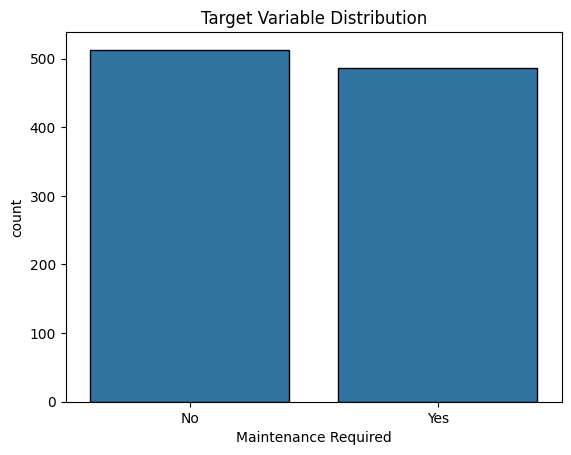

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x=df["Maintenence_Required"], data=df, edgecolor="Black")
plt.xlabel("Maintenance Required")
plt.title("Target Variable Distribution")
plt.show()

In [ ]:
df.isnull().sum()

,0
Pipe_Size_mm,0
Thickness_mm,0
Material,0
Grade,0
Max_Pressure_psi,0
Temperature_C,0
Corrosion_Impact_Percent,0
Thickness_Loss_mm,0
Material_Loss_Percent,0
Time_Years,0


### Univariate Analysis

In [ ]:
# Separate features by type for easier plotting
cat_cols = ['Material', 'Grade']
num_cols = ['Pipe_Size_mm', 'Thickness_mm', 'Max_Pressure_psi', 'Temperature_C',
            'Corrosion_Impact_Percent', 'Thickness_Loss_mm', 'Material_Loss_Percent', 'Time_Years']

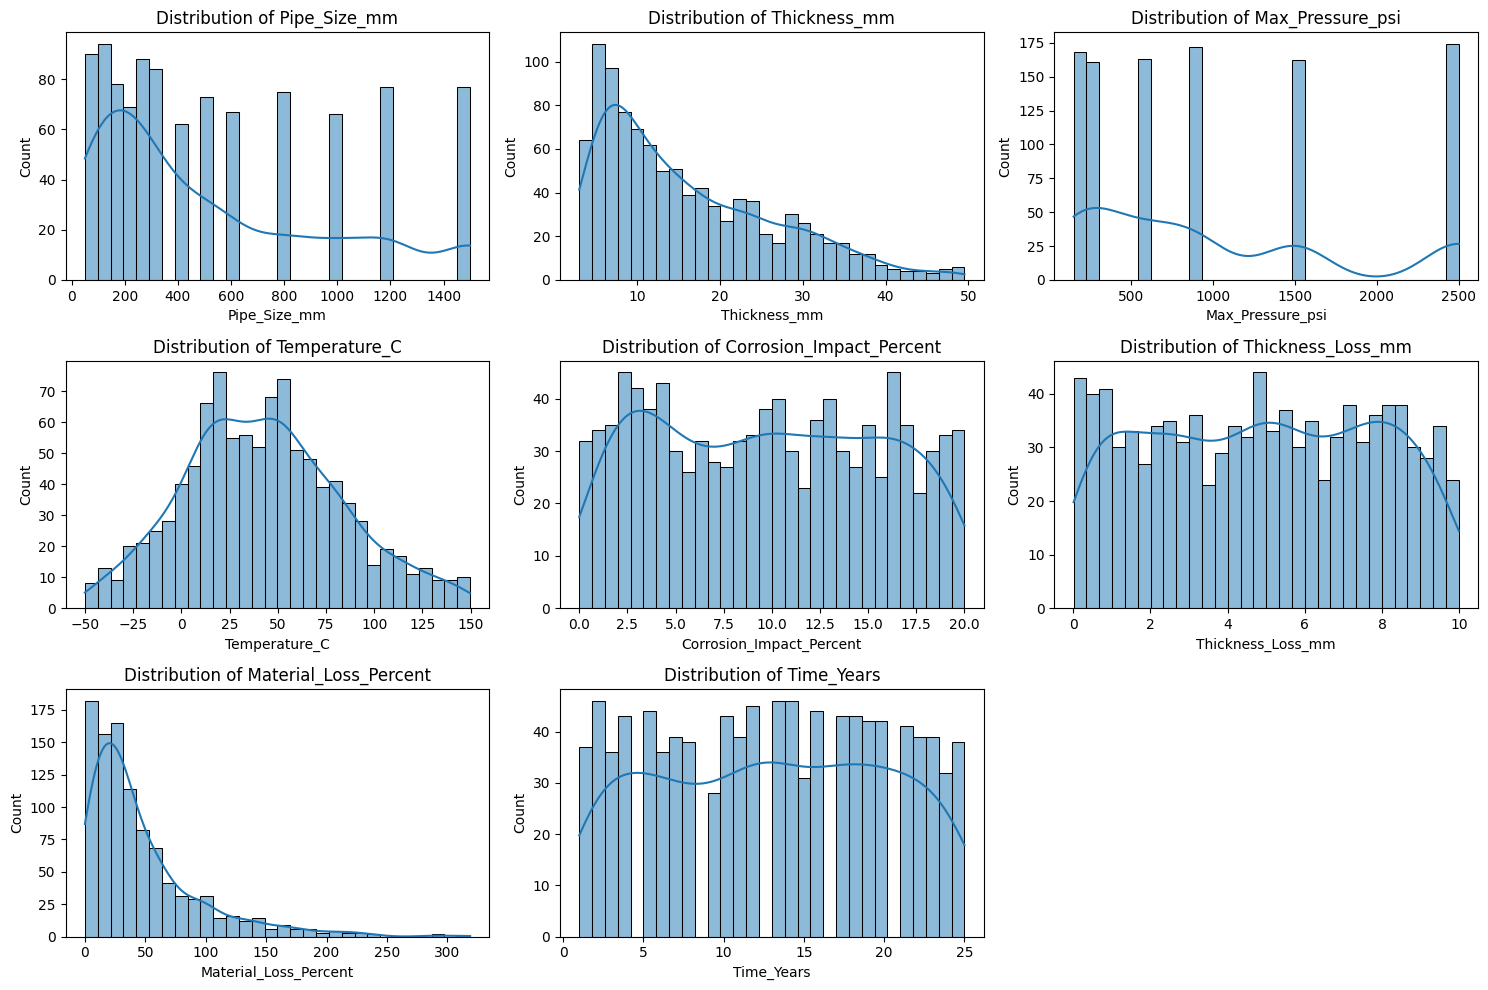

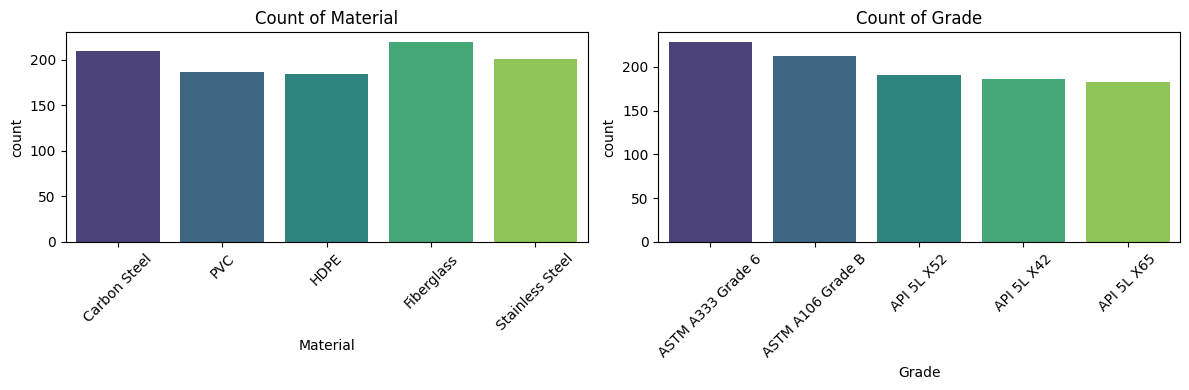

In [ ]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(1, 2, i)
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Bivarite Analysis

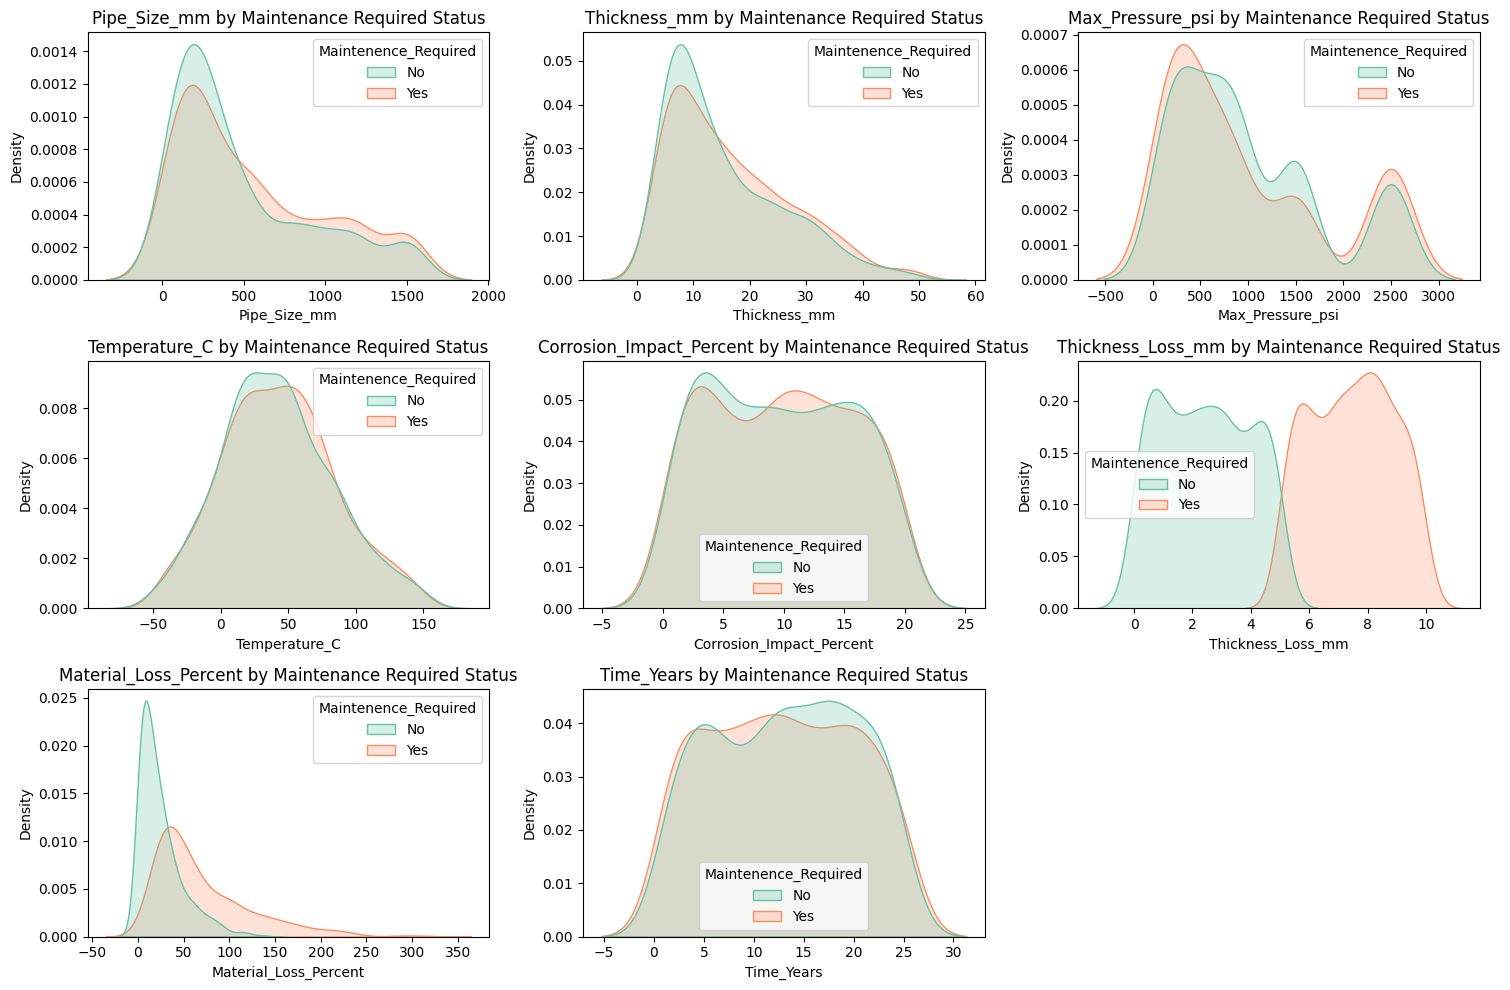

In [ ]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    # Using kdeplot with hue to overlay the distributions
    sns.kdeplot(data=df, x=col, hue='Maintenence_Required', fill=True, common_norm=False, palette='Set2')
    plt.title(f'{col} by Maintenance Required Status')

plt.tight_layout()
plt.show()

### Encoding the Categorical Features

In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(df[cat_cols])
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(cat_cols))
encoded_df.head()

,Material_Carbon Steel,Material_Fiberglass,Material_HDPE,Material_PVC,Material_Stainless Steel,Grade_API 5L X42,Grade_API 5L X52,Grade_API 5L X65,Grade_ASTM A106 Grade B,Grade_ASTM A333 Grade 6
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
df = pd.concat([df, encoded_df], axis=1)
df = df.drop(columns=cat_cols)
df.head()

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years,Maintenence_Required,Material_Carbon Steel,Material_Fiberglass,Material_HDPE,Material_PVC,Material_Stainless Steel,Grade_API 5L X42,Grade_API 5L X52,Grade_API 5L X65,Grade_ASTM A106 Grade B,Grade_ASTM A333 Grade 6
0,800,15.48,300,84.9,16.04,4.91,31.72,2,No,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,800,22.00,150,14.1,7.38,7.32,33.27,4,Yes,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,400,12.05,2500,0.6,2.12,6.32,52.45,7,Yes,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1500,38.72,1500,52.7,5.58,6.20,16.01,19,Yes,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1500,24.32,1500,11.7,12.29,8.58,35.28,20,Yes,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(df["Maintenence_Required"])
df["Maintenence_Required"] = le.transform(df["Maintenence_Required"])
df.head()
df.describe()

,Pipe_Size_mm,Thickness_mm,Max_Pressure_psi,Temperature_C,Corrosion_Impact_Percent,Thickness_Loss_mm,Material_Loss_Percent,Time_Years,Maintenence_Required,Material_Carbon Steel,Material_Fiberglass,Material_HDPE,Material_PVC,Material_Stainless Steel,Grade_API 5L X42,Grade_API 5L X52,Grade_API 5L X65,Grade_ASTM A106 Grade B,Grade_ASTM A333 Grade 6
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,522.000000,16.073530,1004.100000,42.595600,9.745990,4.886300,46.747560,12.961000,0.487000,0.210000,0.219000,0.184000,0.186000,0.201000,0.186000,0.191000,0.18300,0.212000,0.228000
std,443.703587,10.548358,812.843099,41.127071,5.817492,2.901123,46.602553,7.135993,0.500081,0.407512,0.413776,0.387678,0.389301,0.400949,0.389301,0.393286,0.38686,0.408929,0.419753
min,50.000000,3.000000,150.000000,-50.000000,0.000000,0.010000,0.080000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,150.000000,7.357500,300.000000,13.400000,4.492500,2.365000,15.665000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,300.000000,12.930000,900.000000,41.200000,9.720000,4.915000,31.660000,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
75%,800.000000,23.027500,1500.000000,69.150000,14.832500,7.432500,61.035000,19.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
max,1500.000000,49.530000,2500.000000,149.700000,20.000000,9.990000,318.750000,25.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000


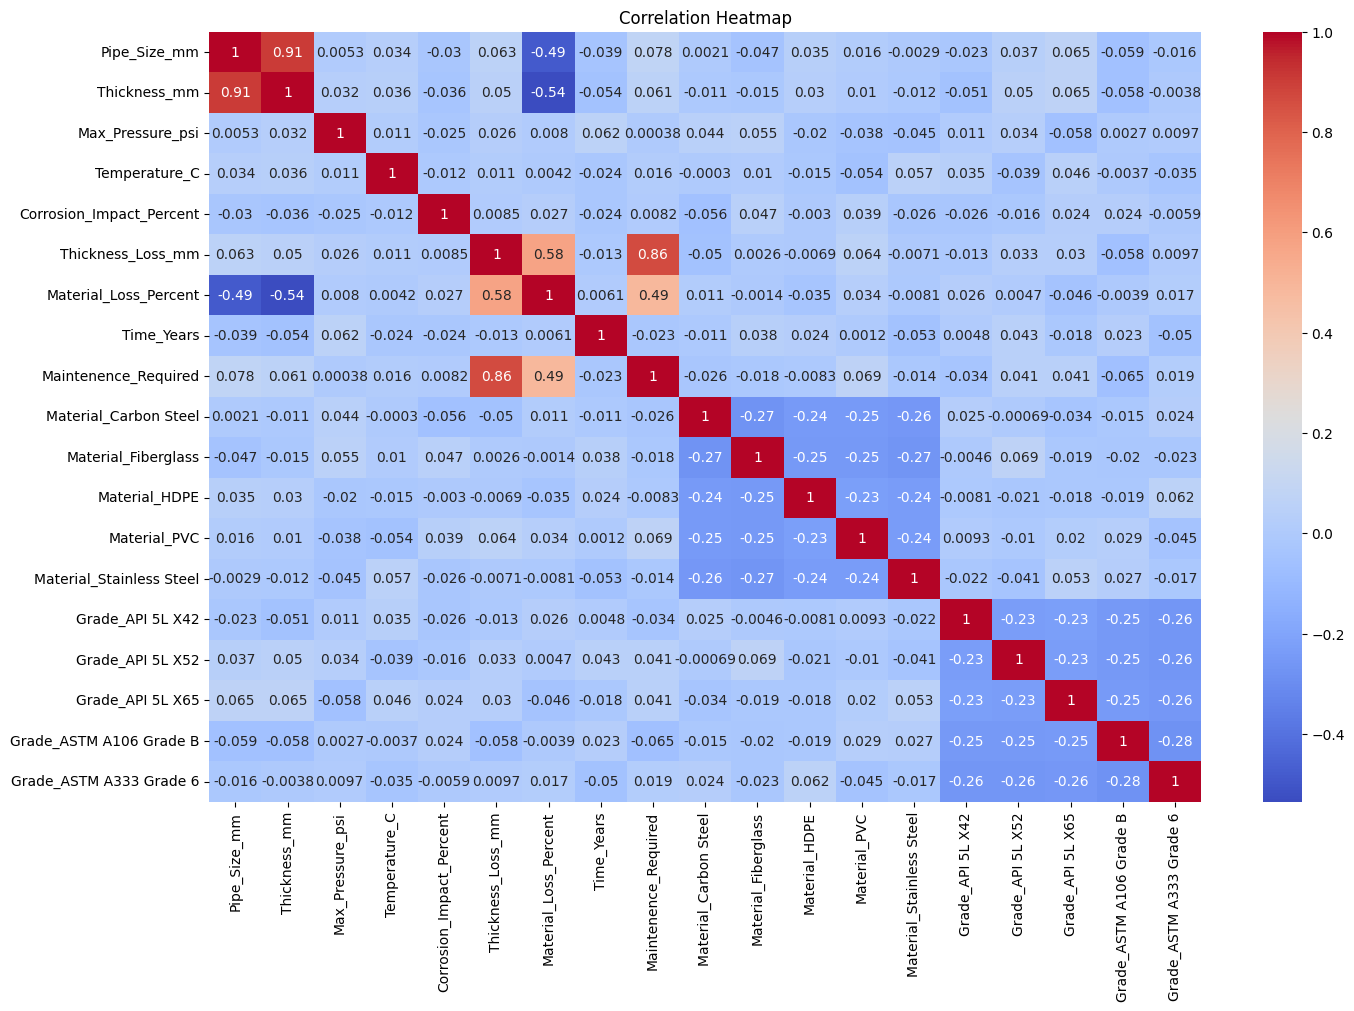

In [ ]:
plt.figure(figsize=(16, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
target_corr = df[['Pipe_Size_mm', 'Thickness_mm', 'Maintenence_Required']].corr()

print("Correlation with Target:")
print(target_corr['Maintenence_Required'][['Pipe_Size_mm', 'Thickness_mm']])

Correlation with Target:
Pipe_Size_mm    0.077982
Thickness_mm    0.061286
Name: Maintenence_Required, dtype: float64


### Model Building

In [ ]:
X_for_log = df.drop(["Maintenence_Required","Thickness_Loss_mm"],axis=1)
y = df["Maintenence_Required"]

#### For 80 - 20 split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_absolute_percentage_error

X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_log_scaled, y_train)

lr_pred = lr_model.predict(X_test_log_scaled)

print("~ Results for Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

~ Results for Logistic Regression
Accuracy: 0.8550

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.86       103
           1       0.84      0.87      0.85        97

    accuracy                           0.85       200
   macro avg       0.85      0.86      0.85       200
weighted avg       0.86      0.85      0.86       200



#### For 75 - 35

In [ ]:
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_log_scaled, y_train)

lr_pred = lr_model.predict(X_test_log_scaled)

print("~ Results for Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

~ Results for Logistic Regression
Accuracy: 0.8280

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83       128
           1       0.83      0.81      0.82       122

    accuracy                           0.83       250
   macro avg       0.83      0.83      0.83       250
weighted avg       0.83      0.83      0.83       250



#### For 70 - 30

In [ ]:
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_log_scaled, y_train)

lr_pred = lr_model.predict(X_test_log_scaled)

print("~ Results for Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

~ Results for Logistic Regression
Accuracy: 0.8400

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.85      0.85       154
           1       0.84      0.83      0.83       146

    accuracy                           0.84       300
   macro avg       0.84      0.84      0.84       300
weighted avg       0.84      0.84      0.84       300



#### For 65 - 35

In [ ]:
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.35, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_log_scaled, y_train)

lr_pred = lr_model.predict(X_test_log_scaled)

print("~ Results for Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

~ Results for Logistic Regression
Accuracy: 0.8486

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85       180
           1       0.85      0.83      0.84       170

    accuracy                           0.85       350
   macro avg       0.85      0.85      0.85       350
weighted avg       0.85      0.85      0.85       350



#### For 60 - 40

In [ ]:
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.4, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_log_scaled, y_train)

lr_pred = lr_model.predict(X_test_log_scaled)

print("~ Results for Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, lr_pred))

~ Results for Logistic Regression
Accuracy: 0.8350

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       205
           1       0.83      0.83      0.83       195

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



### Random Forest

In [ ]:
X_tree = df.drop(["Maintenence_Required","Thickness_Loss_mm"],axis=1)

#### For 80 - 20

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.2, random_state=42, stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)
print("~ Random Forest")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, rf_pred))

~ Random Forest
Accuracy: 0.9300

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       103
           1       0.92      0.94      0.93        97

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.93      0.93      0.93       200



#### For 75 - 35

In [ ]:
X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.25, random_state=42, stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)
print("~ Random Forest")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, rf_pred))

~ Random Forest
Accuracy: 0.9280

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       128
           1       0.93      0.93      0.93       122

    accuracy                           0.93       250
   macro avg       0.93      0.93      0.93       250
weighted avg       0.93      0.93      0.93       250



#### For 70 - 30

In [ ]:
X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.3, random_state=42, stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)
print("~ Random Forest")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, rf_pred))

~ Random Forest
Accuracy: 0.9267

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.93       154
           1       0.92      0.93      0.93       146

    accuracy                           0.93       300
   macro avg       0.93      0.93      0.93       300
weighted avg       0.93      0.93      0.93       300



#### For 65 - 35

In [ ]:
X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.35, random_state=42, stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)
print("~ Random Forest")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, rf_pred))

~ Random Forest
Accuracy: 0.9371

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       180
           1       0.93      0.95      0.94       170

    accuracy                           0.94       350
   macro avg       0.94      0.94      0.94       350
weighted avg       0.94      0.94      0.94       350



#### For 60 - 40

In [ ]:
X_train_rf, X_test_rf, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.4, random_state=42, stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)
print("~ Random Forest")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, rf_pred))

~ Random Forest
Accuracy: 0.9225

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       205
           1       0.91      0.93      0.92       195

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



### K-Nearest Neighbors(KNN)

#### For 80 - 20 split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_knn_scaled = scaler.fit_transform(X_train_knn)
X_test_knn_scaled = scaler.transform(X_test_knn)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_knn_scaled, y_train)
knn_pred = knn_model.predict(X_test_knn_scaled)
print("~ K-Nearest Neighbors Results")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

~ K-Nearest Neighbors Results
Accuracy: 0.5350

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.61      0.58       103
           1       0.52      0.45      0.49        97

    accuracy                           0.54       200
   macro avg       0.53      0.53      0.53       200
weighted avg       0.53      0.54      0.53       200



#### For 75 - 25 split

In [ ]:
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_knn_scaled = scaler.fit_transform(X_train_knn)
X_test_knn_scaled = scaler.transform(X_test_knn)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_knn_scaled, y_train)
knn_pred = knn_model.predict(X_test_knn_scaled)
print("~ K-Nearest Neighbors Results")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

~ K-Nearest Neighbors Results
Accuracy: 0.5520

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.61      0.58       128
           1       0.55      0.49      0.52       122

    accuracy                           0.55       250
   macro avg       0.55      0.55      0.55       250
weighted avg       0.55      0.55      0.55       250



#### For 70 - 30 split

In [ ]:
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.3, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_knn_scaled = scaler.fit_transform(X_train_knn)
X_test_knn_scaled = scaler.transform(X_test_knn)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_knn_scaled, y_train)
knn_pred = knn_model.predict(X_test_knn_scaled)
print("~ K-Nearest Neighbors Results")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

~ K-Nearest Neighbors Results
Accuracy: 0.5733

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.62      0.60       154
           1       0.57      0.52      0.54       146

    accuracy                           0.57       300
   macro avg       0.57      0.57      0.57       300
weighted avg       0.57      0.57      0.57       300



#### For 65 - 35 split

In [ ]:
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.35, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_knn_scaled = scaler.fit_transform(X_train_knn)
X_test_knn_scaled = scaler.transform(X_test_knn)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_knn_scaled, y_train)
knn_pred = knn_model.predict(X_test_knn_scaled)
print("~ K-Nearest Neighbors Results")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

~ K-Nearest Neighbors Results
Accuracy: 0.6000

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.67      0.63       180
           1       0.60      0.53      0.56       170

    accuracy                           0.60       350
   macro avg       0.60      0.60      0.60       350
weighted avg       0.60      0.60      0.60       350



#### For 60 - 40 split

In [ ]:
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.4, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_knn_scaled = scaler.fit_transform(X_train_knn)
X_test_knn_scaled = scaler.transform(X_test_knn)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_knn_scaled, y_train)
knn_pred = knn_model.predict(X_test_knn_scaled)
print("~ K-Nearest Neighbors Results")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, knn_pred))

~ K-Nearest Neighbors Results
Accuracy: 0.6175

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.69      0.65       205
           1       0.62      0.54      0.58       195

    accuracy                           0.62       400
   macro avg       0.62      0.62      0.61       400
weighted avg       0.62      0.62      0.62       400



### Decision Tree Classifier

#### For 80 - 20 split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
X_train_dt, X_test_dt, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.2, random_state=42, stratify=y
)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
dt_pred = dt_model.predict(X_test_dt)
print("~ Decision Tree Results")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

~ Decision Tree Results
Accuracy: 0.9450

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       103
           1       0.94      0.95      0.94        97

    accuracy                           0.94       200
   macro avg       0.94      0.95      0.94       200
weighted avg       0.95      0.94      0.95       200



#### For 75 - 25 split

In [ ]:
X_train_dt, X_test_dt, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.25, random_state=42, stratify=y
)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
dt_pred = dt_model.predict(X_test_dt)
print("~ Decision Tree Results")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

~ Decision Tree Results
Accuracy: 0.9640

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       128
           1       0.96      0.97      0.96       122

    accuracy                           0.96       250
   macro avg       0.96      0.96      0.96       250
weighted avg       0.96      0.96      0.96       250



#### For 70 - 30 split

In [ ]:
X_train_dt, X_test_dt, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.3, random_state=42, stratify=y
)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
dt_pred = dt_model.predict(X_test_dt)
print("~ Decision Tree Results")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

~ Decision Tree Results
Accuracy: 0.9700

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       154
           1       0.97      0.97      0.97       146

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



#### For 65 - 35 split

In [ ]:
X_train_dt, X_test_dt, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.35, random_state=42, stratify=y
)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
dt_pred = dt_model.predict(X_test_dt)
print("~ Decision Tree Results")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

~ Decision Tree Results
Accuracy: 0.9543

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       180
           1       0.95      0.95      0.95       170

    accuracy                           0.95       350
   macro avg       0.95      0.95      0.95       350
weighted avg       0.95      0.95      0.95       350



#### For 60 - 40 split

In [ ]:
X_train_dt, X_test_dt, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.4, random_state=42, stratify=y
)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_dt, y_train)
dt_pred = dt_model.predict(X_test_dt)
print("~ Decision Tree Results")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, dt_pred))

~ Decision Tree Results
Accuracy: 0.9450

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       205
           1       0.93      0.95      0.94       195

    accuracy                           0.94       400
   macro avg       0.94      0.95      0.94       400
weighted avg       0.95      0.94      0.95       400



### Support Vector Classifier

#### For 80 - 20 split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
X_train_svc, X_test_svc, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_svc_scaled = scaler.fit_transform(X_train_svc)
X_test_svc_scaled = scaler.transform(X_test_svc)
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_svc_scaled, y_train)
svc_pred = svc_model.predict(X_test_svc_scaled)
print("~ Support Vector Classifier (SVC) Results")
print(f"Accuracy: {accuracy_score(y_test, svc_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_pred))

~ Support Vector Classifier (SVC) Results
Accuracy: 0.8100

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.76      0.80       103
           1       0.77      0.87      0.82        97

    accuracy                           0.81       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200



#### For 75 - 25

In [ ]:
X_train_svc, X_test_svc, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_svc_scaled = scaler.fit_transform(X_train_svc)
X_test_svc_scaled = scaler.transform(X_test_svc)
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_svc_scaled, y_train)
svc_pred = svc_model.predict(X_test_svc_scaled)
print("~ Support Vector Classifier (SVC) Results")
print(f"Accuracy: {accuracy_score(y_test, svc_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_pred))

~ Support Vector Classifier (SVC) Results
Accuracy: 0.7800

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.76      0.78       128
           1       0.76      0.80      0.78       122

    accuracy                           0.78       250
   macro avg       0.78      0.78      0.78       250
weighted avg       0.78      0.78      0.78       250



#### For 70 - 30

In [ ]:
X_train_svc, X_test_svc, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.3, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_svc_scaled = scaler.fit_transform(X_train_svc)
X_test_svc_scaled = scaler.transform(X_test_svc)
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_svc_scaled, y_train)
svc_pred = svc_model.predict(X_test_svc_scaled)
print("~ Support Vector Classifier (SVC) Results")
print(f"Accuracy: {accuracy_score(y_test, svc_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_pred))

~ Support Vector Classifier (SVC) Results
Accuracy: 0.7733

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.76      0.77       154
           1       0.76      0.79      0.77       146

    accuracy                           0.77       300
   macro avg       0.77      0.77      0.77       300
weighted avg       0.77      0.77      0.77       300



#### For 65 - 35

In [ ]:
X_train_svc, X_test_svc, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.35, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_svc_scaled = scaler.fit_transform(X_train_svc)
X_test_svc_scaled = scaler.transform(X_test_svc)
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_svc_scaled, y_train)
svc_pred = svc_model.predict(X_test_svc_scaled)
print("~ Support Vector Classifier (SVC) Results")
print(f"Accuracy: {accuracy_score(y_test, svc_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_pred))

~ Support Vector Classifier (SVC) Results
Accuracy: 0.8114

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       180
           1       0.79      0.83      0.81       170

    accuracy                           0.81       350
   macro avg       0.81      0.81      0.81       350
weighted avg       0.81      0.81      0.81       350



#### For 60 - 40

In [ ]:
X_train_svc, X_test_svc, y_train, y_test = train_test_split(
    X_for_log, y, test_size=0.4, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_svc_scaled = scaler.fit_transform(X_train_svc)
X_test_svc_scaled = scaler.transform(X_test_svc)
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_svc_scaled, y_train)
svc_pred = svc_model.predict(X_test_svc_scaled)
print("~ Support Vector Classifier (SVC) Results")
print(f"Accuracy: {accuracy_score(y_test, svc_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, svc_pred))

~ Support Vector Classifier (SVC) Results
Accuracy: 0.7975

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.75      0.79       205
           1       0.76      0.85      0.80       195

    accuracy                           0.80       400
   macro avg       0.80      0.80      0.80       400
weighted avg       0.80      0.80      0.80       400



### Naive Bayes

#### For 80 - 20

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
X_train_nb, X_test_nb, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.2, random_state=42, stratify=y
)
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)
nb_pred = nb_model.predict(X_test_nb)
print("~ Gaussian Naive Bayes Results")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_pred))

~ Gaussian Naive Bayes Results
Accuracy: 0.6750

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.80      0.72       103
           1       0.72      0.55      0.62        97

    accuracy                           0.68       200
   macro avg       0.68      0.67      0.67       200
weighted avg       0.68      0.68      0.67       200



#### For 75 - 25 split

In [ ]:
X_train_nb, X_test_nb, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.25, random_state=42, stratify=y
)
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)
nb_pred = nb_model.predict(X_test_nb)
print("~ Gaussian Naive Bayes Results")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_pred))

~ Gaussian Naive Bayes Results
Accuracy: 0.7000

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.80      0.73       128
           1       0.74      0.60      0.66       122

    accuracy                           0.70       250
   macro avg       0.71      0.70      0.70       250
weighted avg       0.71      0.70      0.70       250



#### For 70 - 30 split

In [ ]:
X_train_nb, X_test_nb, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.3, random_state=42, stratify=y
)
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)
nb_pred = nb_model.predict(X_test_nb)
print("~ Gaussian Naive Bayes Results")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_pred))

~ Gaussian Naive Bayes Results
Accuracy: 0.7400

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.84      0.77       154
           1       0.79      0.63      0.70       146

    accuracy                           0.74       300
   macro avg       0.75      0.74      0.74       300
weighted avg       0.75      0.74      0.74       300



#### For 65 - 35 split

In [ ]:
X_train_nb, X_test_nb, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.35, random_state=42, stratify=y
)
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)
nb_pred = nb_model.predict(X_test_nb)
print("~ Gaussian Naive Bayes Results")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_pred))

~ Gaussian Naive Bayes Results
Accuracy: 0.7286

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.87      0.77       180
           1       0.81      0.58      0.67       170

    accuracy                           0.73       350
   macro avg       0.75      0.72      0.72       350
weighted avg       0.75      0.73      0.72       350



#### For 60 - 40 split

In [ ]:
X_train_nb, X_test_nb, y_train, y_test = train_test_split(
    X_tree, y, test_size=0.4, random_state=42, stratify=y
)
nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train)
nb_pred = nb_model.predict(X_test_nb)
print("~ Gaussian Naive Bayes Results")
print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, nb_pred))

~ Gaussian Naive Bayes Results
Accuracy: 0.7175

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.84      0.75       205
           1       0.78      0.59      0.67       195

    accuracy                           0.72       400
   macro avg       0.73      0.71      0.71       400
weighted avg       0.73      0.72      0.71       400



### XG Boost

#### 80-20

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
X = df.drop(["Maintenence_Required","Thickness_Loss_mm"],axis=1)
y = df["Maintenence_Required"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.975

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98       103
           1       0.96      0.99      0.97        97

    accuracy                           0.97       200
   macro avg       0.97      0.98      0.97       200
weighted avg       0.98      0.97      0.98       200



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.96

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       128
           1       0.96      0.96      0.96       122

    accuracy                           0.96       250
   macro avg       0.96      0.96      0.96       250
weighted avg       0.96      0.96      0.96       250



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.97

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       154
           1       0.97      0.97      0.97       146

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.35,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9628571428571429

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       180
           1       0.97      0.95      0.96       170

    accuracy                           0.96       350
   macro avg       0.96      0.96      0.96       350
weighted avg       0.96      0.96      0.96       350



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.945

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       205
           1       0.93      0.95      0.94       195

    accuracy                           0.94       400
   macro avg       0.94      0.95      0.94       400
weighted avg       0.95      0.94      0.95       400



In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# 1. Data Preprocessing
# Convert binary target to 0 and 1
df['Maintenence_Required'] = df['Maintenence_Required'].map({'Yes': 1, 'No': 0})

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_for_log, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features (important for Logistic Regression and SVC)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Define Models and Hyperparameter Grids
model_params = {
    'Logistic_Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'params': {
            'C': [0.01, 0.1, 1, 10],
            'solver': ['liblinear', 'lbfgs']
        }
    },
    'Support_Vector_Machine': {
        'model': SVC(random_state=42),
        'params': {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto']
        }
    }
}

# 3. Execute Grid Search
best_models = {}
results = []

print("Running Grid Search...\n" + "-"*30)
for model_name, mp in model_params.items():
    clf = GridSearchCV(mp['model'], mp['params'], cv=5, scoring='accuracy', n_jobs=-1)
    clf.fit(X_train_scaled, y_train)

    # Store best model
    best_models[model_name] = clf.best_estimator_

    # Record results
    results.append({
        'Model': model_name,
        'Best Score (CV Accuracy)': clf.best_score_,
        'Best Params': clf.best_params_
    })

# Display Results cleanly
results_df = pd.DataFrame(results)
display(results_df)

Running Grid Search...
------------------------------


,Model,Best Score (CV Accuracy),Best Params
0,Logistic_Regression,0.84125,"{'C': 10, 'solver': 'liblinear'}"
1,Support_Vector_Machine,0.84750,"{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}"


In [ ]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20]
}

# 3. Execute Grid Search
print("Running Grid Search for Random Forest...\n" + "-"*40)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# 4. Display Results
print(f"Best CV Accuracy: {grid_search.best_score_:.4f}")
print("Best Parameters:")
for param, value in grid_search.best_params_.items():
    print(f"  - {param}: {value}")

# Access the best configured model for future predictions
best_rf_model = grid_search.best_estimator_

Running Grid Search for Random Forest...
----------------------------------------
Best CV Accuracy: 0.9213
Best Parameters:
  - max_depth: 10
  - n_estimators: 50


#### ANN

#### 80 - 20

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=16, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.5234 - loss: 0.7694 - val_accuracy: 0.5063 - val_loss: 0.7361
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5188 - loss: 0.7222 - val_accuracy: 0.5250 - val_loss: 0.7114
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5359 - loss: 0.7015 - val_accuracy: 0.5125 - val_loss: 0.6955
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5734 - loss: 0.6859 - val_accuracy: 0.5500 - val_loss: 0.6871
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5984 - loss: 0.6784 - val_accuracy: 0.5625 - val_loss: 0.6794
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5844 - loss: 0.6752 - val_accuracy: 0.6000 - val_loss: 0.6735
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5969 - loss: 0.6687 - val_accuracy: 0.6125 - val_loss: 0.6673
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6328 - loss: 0.6593

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step


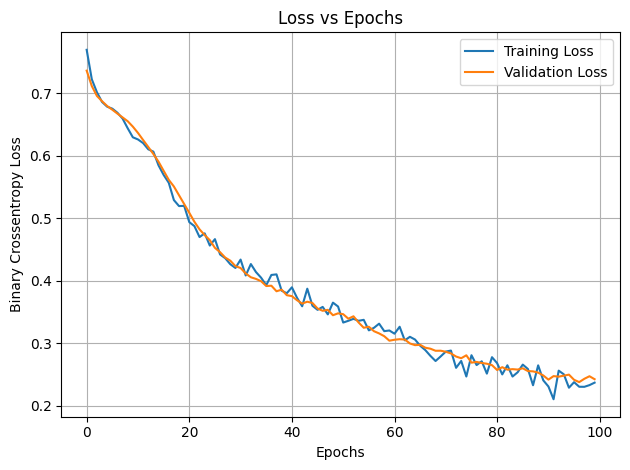

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=16, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.5188 - loss: 0.7447 - val_accuracy: 0.4625 - val_loss: 0.7349
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5531 - loss: 0.6968 - val_accuracy: 0.5250 - val_loss: 0.6951
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5531 - loss: 0.6723 - val_accuracy: 0.5625 - val_loss: 0.6768
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5734 - loss: 0.6620 - val_accuracy: 0.5813 - val_loss: 0.6668
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6266 - loss: 0.6370 - val_accuracy: 0.6062 - val_loss: 0.6567
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6172 - loss: 0.6426 - val_accuracy: 0.6438 - val_loss: 0.6473
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6500 - loss: 0.6326 - val_accuracy: 0.6562 - val_loss: 0.6380
Epoch 8/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6750 - loss:

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


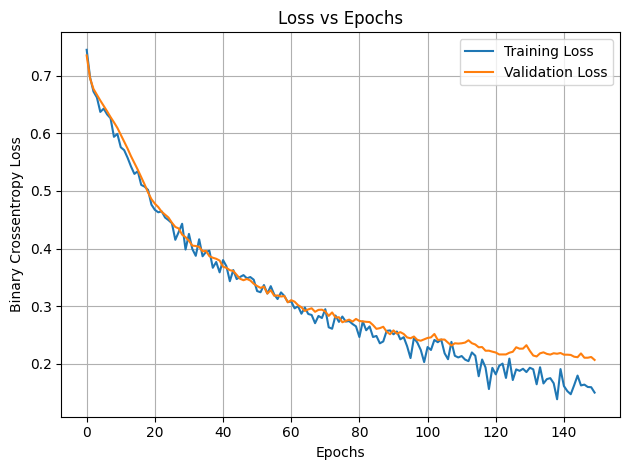

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=32, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=16, activation='relu'),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.5219 - loss: 0.7064 - val_accuracy: 0.5188 - val_loss: 0.7067
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5484 - loss: 0.6839 - val_accuracy: 0.4938 - val_loss: 0.6951
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5766 - loss: 0.6780 - val_accuracy: 0.5188 - val_loss: 0.6853
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6125 - loss: 0.6640 - val_accuracy: 0.5500 - val_loss: 0.6762
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.6531 - loss: 0.6411 - val_accuracy: 0.5938 - val_loss: 0.6627
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6547 - loss: 0.6353 - val_accuracy: 0.6375 - val_loss: 0.6419
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6781 - loss: 0.6130 - val_accuracy: 0.6875 - val_loss: 0.6154
Epoch 8/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7016 - loss:

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


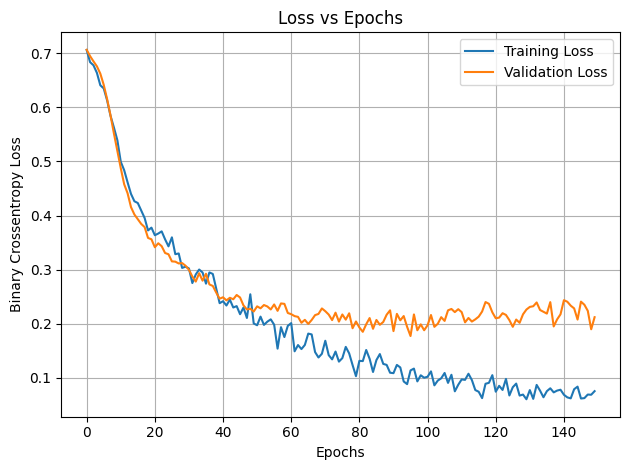

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=32, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=16, activation='relu'),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.5188 - loss: 0.6955 - val_accuracy: 0.5625 - val_loss: 0.6827
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5500 - loss: 0.6801 - val_accuracy: 0.5625 - val_loss: 0.6703
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5984 - loss: 0.6718 - val_accuracy: 0.6500 - val_loss: 0.6607
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6156 - loss: 0.6631 - val_accuracy: 0.6625 - val_loss: 0.6513
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6453 - loss: 0.6496 - val_accuracy: 0.6687 - val_loss: 0.6396
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6656 - loss: 0.6306 - val_accuracy: 0.6875 - val_loss: 0.6222
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6984 - loss: 0.6069 - val_accuracy: 0.7063 - val_loss: 0.6008
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7078 - loss:

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step


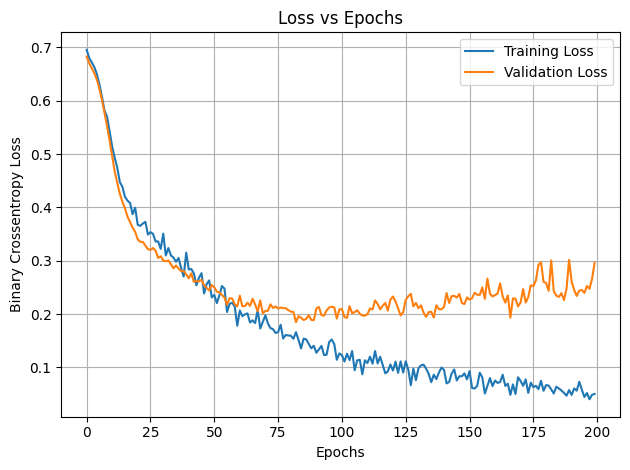

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=64, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=32, activation='relu'),
    Dense(units=16, activation='relu'),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.4984 - loss: 0.7154 - val_accuracy: 0.6500 - val_loss: 0.6645
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6000 - loss: 0.6600 - val_accuracy: 0.7000 - val_loss: 0.6423
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6578 - loss: 0.6347 - val_accuracy: 0.6750 - val_loss: 0.6174
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7109 - loss: 0.5917 - val_accuracy: 0.6938 - val_loss: 0.5795
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7234 - loss: 0.5480 - val_accuracy: 0.7188 - val_loss: 0.5353
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7719 - loss: 0.4824 - val_accuracy: 0.7375 - val_loss: 0.4897
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7828 - loss: 0.4552 - val_accuracy: 0.7500 - val_loss: 0.4550
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8062 - loss: 0.

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step


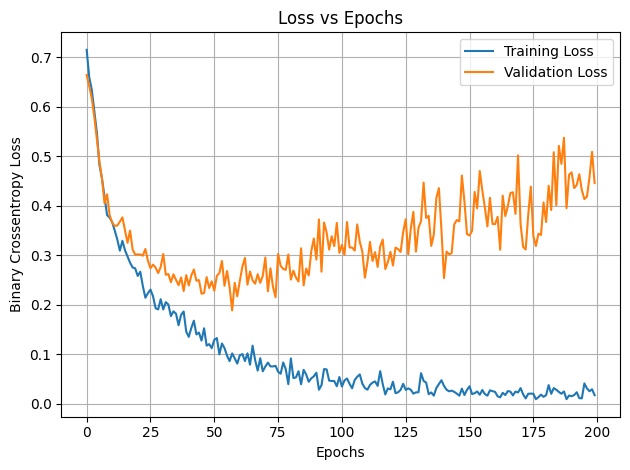

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=64, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=32, activation='relu'),
    Dense(units=16, activation='relu'),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=250,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.5125 - loss: 0.6975 - val_accuracy: 0.5813 - val_loss: 0.6825
Epoch 2/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5813 - loss: 0.6783 - val_accuracy: 0.6187 - val_loss: 0.6699
Epoch 3/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6641 - loss: 0.6516 - val_accuracy: 0.6938 - val_loss: 0.6499
Epoch 4/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6844 - loss: 0.6311 - val_accuracy: 0.6812 - val_loss: 0.6211
Epoch 5/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7328 - loss: 0.5868 - val_accuracy: 0.7000 - val_loss: 0.5854
Epoch 6/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7563 - loss: 0.5392 - val_accuracy: 0.6938 - val_loss: 0.5533
Epoch 7/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7812 - loss: 0.4833 - val_accuracy: 0.7437 - val_loss: 0.5092
Epoch 8/250
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7781 - loss:

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step


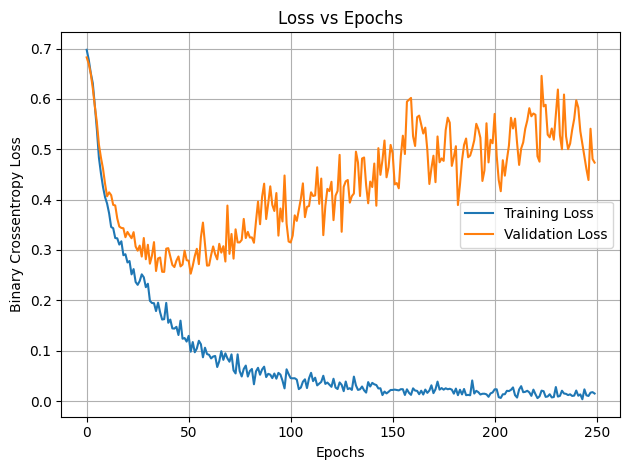

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Restore the correct target values to fix the NaN issue
# Convert original Condition to binary Maintenance Required targets correctly
original_df = pd.read_csv('/content/market_pipe_thickness_loss_dataset.csv')
df['Maintenence_Required'] = original_df['Condition'].map({'Moderate': 0, 'Critical': 1, 'Normal': 0})

# 2. Define Features and Target
X = df.drop(['Maintenence_Required', 'Thickness_Loss_mm'], axis=1)
y = df['Maintenence_Required']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build the ANN Model
model = Sequential([
    Dense(units=64, activation='relu', input_dim=X_train_scaled.shape[1]),
    Dropout(0.2),
    Dense(units=32, activation='relu'),
    Dense(units=16, activation='relu'),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

# 6. Compile the Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 7. Train the Model
print('Training the ANN model...')
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# 8. Evaluate the Model
print('\nEvaluating on Test Data...')
loss, accuracy = model.evaluate(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.4f}')

Training the ANN model...
Epoch 1/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.5234 - loss: 0.6944 - val_accuracy: 0.5500 - val_loss: 0.6860
Epoch 2/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5922 - loss: 0.6724 - val_accuracy: 0.5750 - val_loss: 0.6713
Epoch 3/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6281 - loss: 0.6518 - val_accuracy: 0.6438 - val_loss: 0.6543
Epoch 4/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6938 - loss: 0.6134 - val_accuracy: 0.6562 - val_loss: 0.6270
Epoch 5/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7078 - loss: 0.5718 - val_accuracy: 0.6812 - val_loss: 0.5905
Epoch 6/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7672 - loss: 0.5060 - val_accuracy: 0.7000 - val_loss: 0.5455
Epoch 7/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7719 - loss: 0.4691 - val_accuracy: 0.7750 - val_loss: 0.4900
Epoch 8/300
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8016 - loss: 0.4377

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step


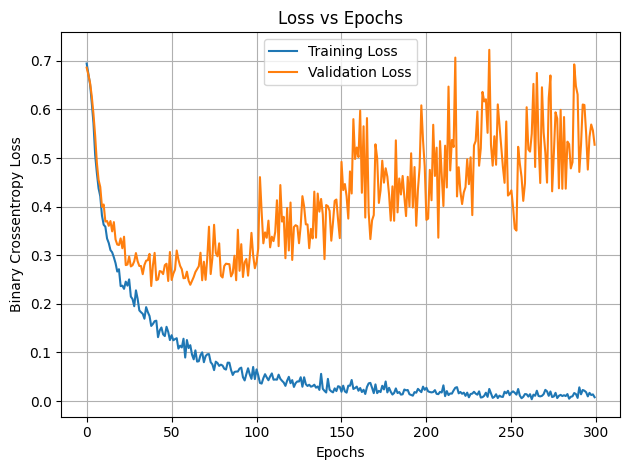

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Loss Curve
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Binary Crossentropy Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()